# 03. Géométrie riemannienne : espace tangent et MDM

**Idée :** au lieu d'apprendre des filtres spatiaux (CSP), on décrit chaque essai directement par sa
**matrice de covariance spatiale** C (22 x 22) : sa diagonale contient la puissance de chaque électrode
dans la bande 8-30 Hz, ses termes hors diagonale la façon dont les électrodes varient ensemble.
L'ERD, baisse de puissance localisée, se lit donc directement dans C.

**Méthodes** (dans `src/pipelines.py`) :
- **TS+LR** : covariances (estimateur OAS), projection dans l'espace tangent autour de la moyenne
  riemannienne des essais d'apprentissage, puis régression logistique ;
- **MDM** : une moyenne riemannienne par classe, chaque essai est attribué à la moyenne la plus proche.

Même boucle, mêmes essais, mêmes plis que CSP + LDA (phase 2). Calculs : `src/phase3_riemann.py`.

In [1]:
import os, sys
from pathlib import Path
RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RACINE); sys.path.insert(0, str(RACINE))
import pandas as pd
from IPython.display import Image, display

## 1. Pourquoi les covariances vivent sur une variété

Une matrice de covariance est **symétrique définie positive** (SPD) : toute combinaison des électrodes
a une variance strictement positive. Cet ensemble n'est pas un espace vectoriel « plat » :
- la différence de deux covariances peut ne plus être une covariance (variances négatives) ;
- en 2 x 2, les matrices [[a, b], [b, c]] SPD vérifient a > 0 et ac > b² : elles remplissent l'intérieur
  d'un **cône**, et le bord du cône (matrices singulières) est à distance infinie.

La géométrie riemannienne mesure les distances *le long* de cette surface courbe. Sa distance,
δ(A, B) = ||log(A^(-1/2) B A^(-1/2))||, a deux propriétés utiles pour l'EEG :
- **invariance affine** : elle ne change pas si on applique la même transformation linéaire inversible
  aux deux essais (par exemple un changement de référence ou de gain des électrodes) ;
- **pas d'effet de gonflement** : la moyenne euclidienne de deux covariances de même volume mais
  d'orientations différentes a un volume (déterminant) plus grand que chacune ; la moyenne
  riemannienne le conserve.

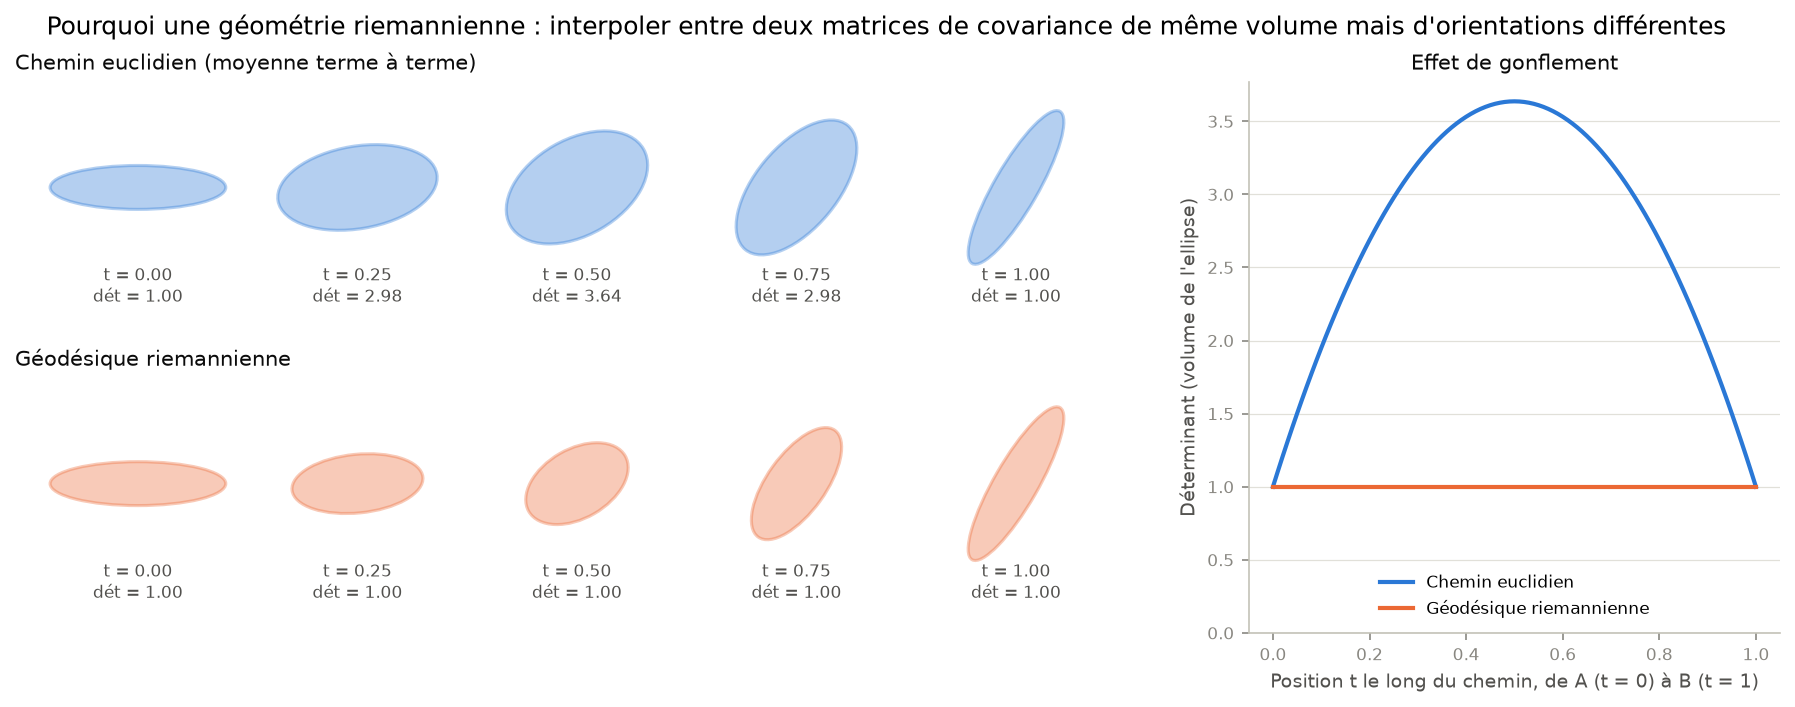

In [2]:
display(Image("reports/figures/phase3_intuition_variete.png"))

**L'espace tangent** : comme on « déplie » localement la Terre sur une carte plane autour d'une ville,
on projette toutes les covariances sur le plan tangent à la variété au point moyen des essais
d'apprentissage. Près de ce point, les distances sont bien conservées, et chaque matrice devient un
vecteur de 22 x 23 / 2 = 253 nombres, utilisable par n'importe quel classifieur linéaire.
Le point moyen est appris dans `TangentSpace.fit`, donc dans le pipeline : il est réappris à chaque pli.

## 2. Résultats : moyenne ± écart-type sur les 9 sujets

In [3]:
resume = pd.read_csv("results/phase3_resume.csv")
resume.pivot_table(index="methode", columns=["tache", "evaluation"], values="kappa_moyen").round(3)

tache      4classes        binaire       
evaluation    inter  intra   inter  intra
methode                                  
CSP+LDA       0.499  0.552   0.571  0.561
MDM           0.432  0.468   0.528  0.515
TS+LR         0.562  0.593   0.591  0.611

In [4]:
resume.round(3)

,methode,tache,evaluation,accuracy_moyenne,accuracy_ecart_type,kappa_moyen,kappa_ecart_type,kappa_min,kappa_max
0,CSP+LDA,4classes,inter,0.624,0.172,0.499,0.229,0.144,0.745
1,CSP+LDA,4classes,intra,0.664,0.188,0.552,0.250,0.134,0.806
2,CSP+LDA,binaire,inter,0.786,0.166,0.571,0.331,0.111,0.944
3,CSP+LDA,binaire,intra,0.780,0.168,0.561,0.336,0.069,0.938
4,MDM,4classes,inter,0.574,0.141,0.432,0.188,0.171,0.657
5,MDM,4classes,intra,0.601,0.160,0.468,0.214,0.160,0.674
6,MDM,binaire,inter,0.764,0.170,0.528,0.339,0.153,0.958
7,MDM,binaire,intra,0.757,0.161,0.515,0.323,0.104,0.938
8,TS+LR,4classes,inter,0.671,0.169,0.562,0.225,0.259,0.819
9,TS+LR,4classes,intra,0.695,0.182,0.593,0.243,0.194,0.850


## 3. Comparaison appariée et test de Wilcoxon

Chaque sujet est sa propre référence : on compare les méthodes *sur le même sujet*, ce qui élimine
la très forte variabilité entre sujets. Avec 9 sujets, le test des rangs signés de Wilcoxon
(non paramétrique, sans hypothèse de normalité) a une p-valeur minimale de 2/512, soit environ 0,004.
12 tests sont faits (3 paires x 2 tâches x 2 évaluations) : la correction de Holm contrôle le risque
d'obtenir au moins un faux positif.

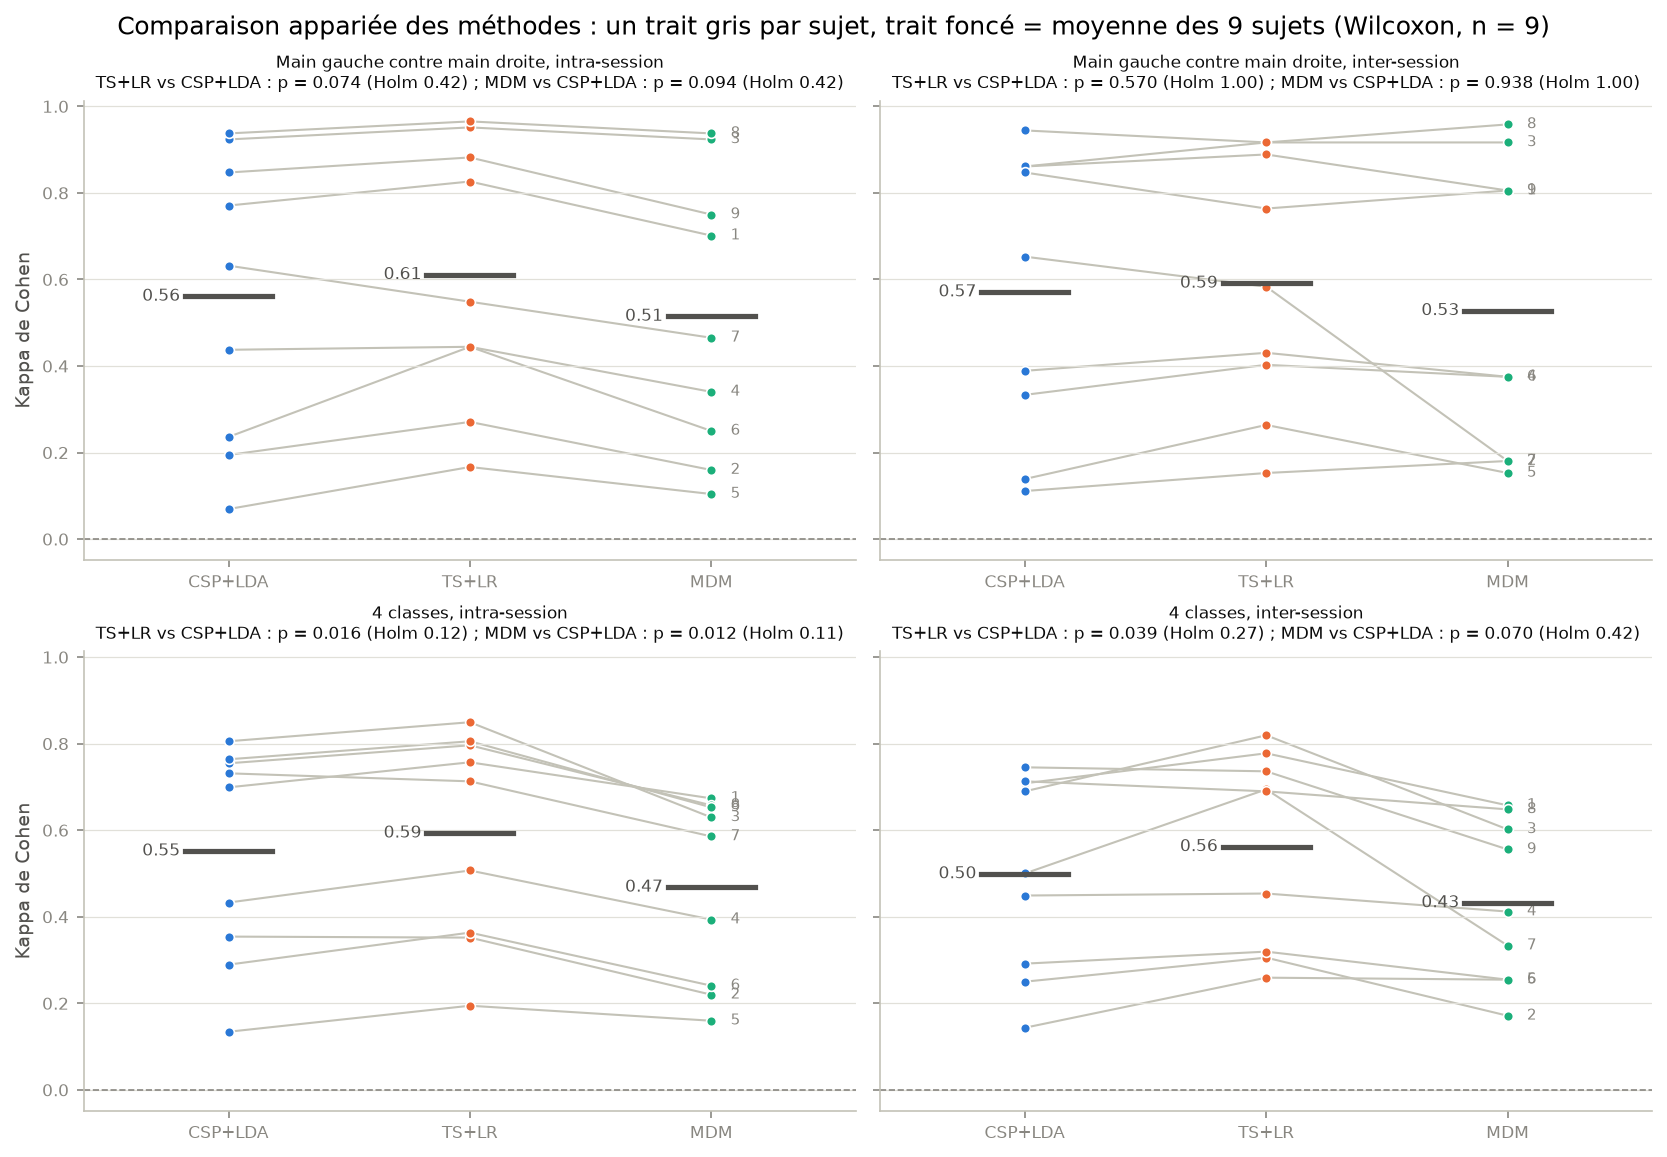

In [5]:
display(Image("reports/figures/phase3_comparaison_methodes.png"))

In [6]:
pd.read_csv("results/phase3_wilcoxon.csv")[["tache", "evaluation", "methode_a", "methode_b",
    "kappa_moyen_a", "kappa_moyen_b", "difference_moyenne", "sujets_a_meilleur", "p_valeur",
    "p_valeur_holm"]].round(3)

,tache,evaluation,methode_a,methode_b,kappa_moyen_a,kappa_moyen_b,difference_moyenne,sujets_a_meilleur,p_valeur,p_valeur_holm
0,binaire,intra,TS+LR,CSP+LDA,0.611,0.561,0.050,8,0.074,0.422
1,binaire,intra,MDM,CSP+LDA,0.515,0.561,-0.046,2,0.094,0.422
2,binaire,intra,TS+LR,MDM,0.611,0.515,0.096,9,0.004,0.047
3,binaire,inter,TS+LR,CSP+LDA,0.591,0.571,0.020,6,0.570,1.000
4,binaire,inter,MDM,CSP+LDA,0.528,0.571,-0.043,4,0.938,1.000
5,binaire,inter,TS+LR,MDM,0.591,0.528,0.063,5,0.219,0.656
6,4classes,intra,TS+LR,CSP+LDA,0.593,0.552,0.041,7,0.016,0.125
7,4classes,intra,MDM,CSP+LDA,0.468,0.552,-0.084,1,0.012,0.106
8,4classes,intra,TS+LR,MDM,0.593,0.468,0.125,9,0.004,0.047
9,4classes,inter,TS+LR,CSP+LDA,0.562,0.499,0.063,7,0.039,0.273


## 4. Protocole de la compétition : 4 classes, session 1 vers session 2

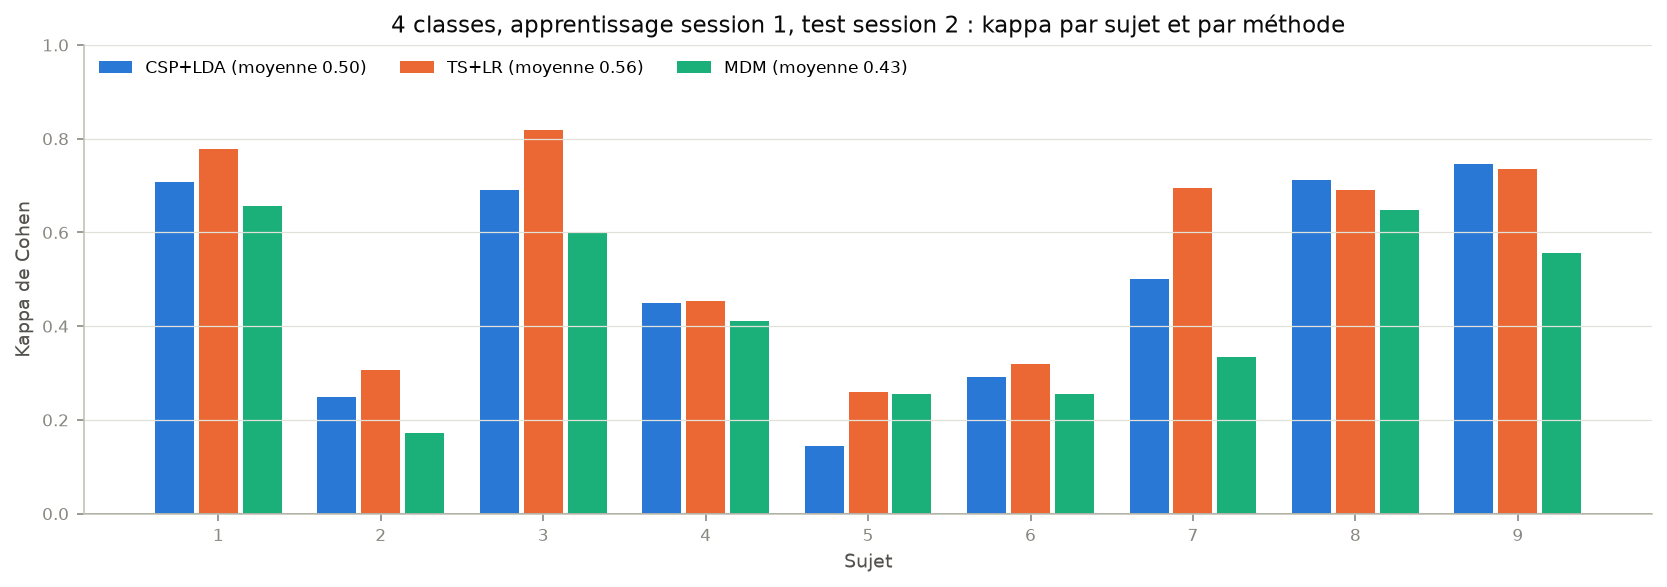

In [7]:
display(Image("reports/figures/phase3_kappa_4classes_inter.png"))

In [8]:
par_sujet = pd.read_csv("results/phase3_scores_par_sujet.csv")
par_sujet[(par_sujet.tache == "4classes") & (par_sujet.evaluation == "inter")].pivot(
    index="sujet", columns="methode", values="kappa").round(3)

methode,CSP+LDA,MDM,TS+LR
sujet,,,
1,0.708,0.657,0.778
2,0.250,0.171,0.306
3,0.690,0.602,0.819
4,0.449,0.412,0.454
5,0.144,0.255,0.259
6,0.292,0.255,0.319
7,0.500,0.333,0.694
8,0.713,0.648,0.690
9,0.745,0.556,0.736
